## Delivery Activity Across AOI Types (Flag 14)

### Dataset Overview

Ten linked courier workdays containing 148 local visits, 333 deliveries, and 10164 timestamped GPS observations across office and residential AOIs.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Investigate how the courier's delivery activity differs across AOI types.

Role: Last-mile delivery operations analyst


Category: AOI delivery batching, travel efficiency, and time-of-day allocation


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "delivery_visits.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the number of completed deliveries per visit differ between Residential and Office AOIs?

#### Analysis action

Compare the within-type distribution of completed deliveries per local visit.

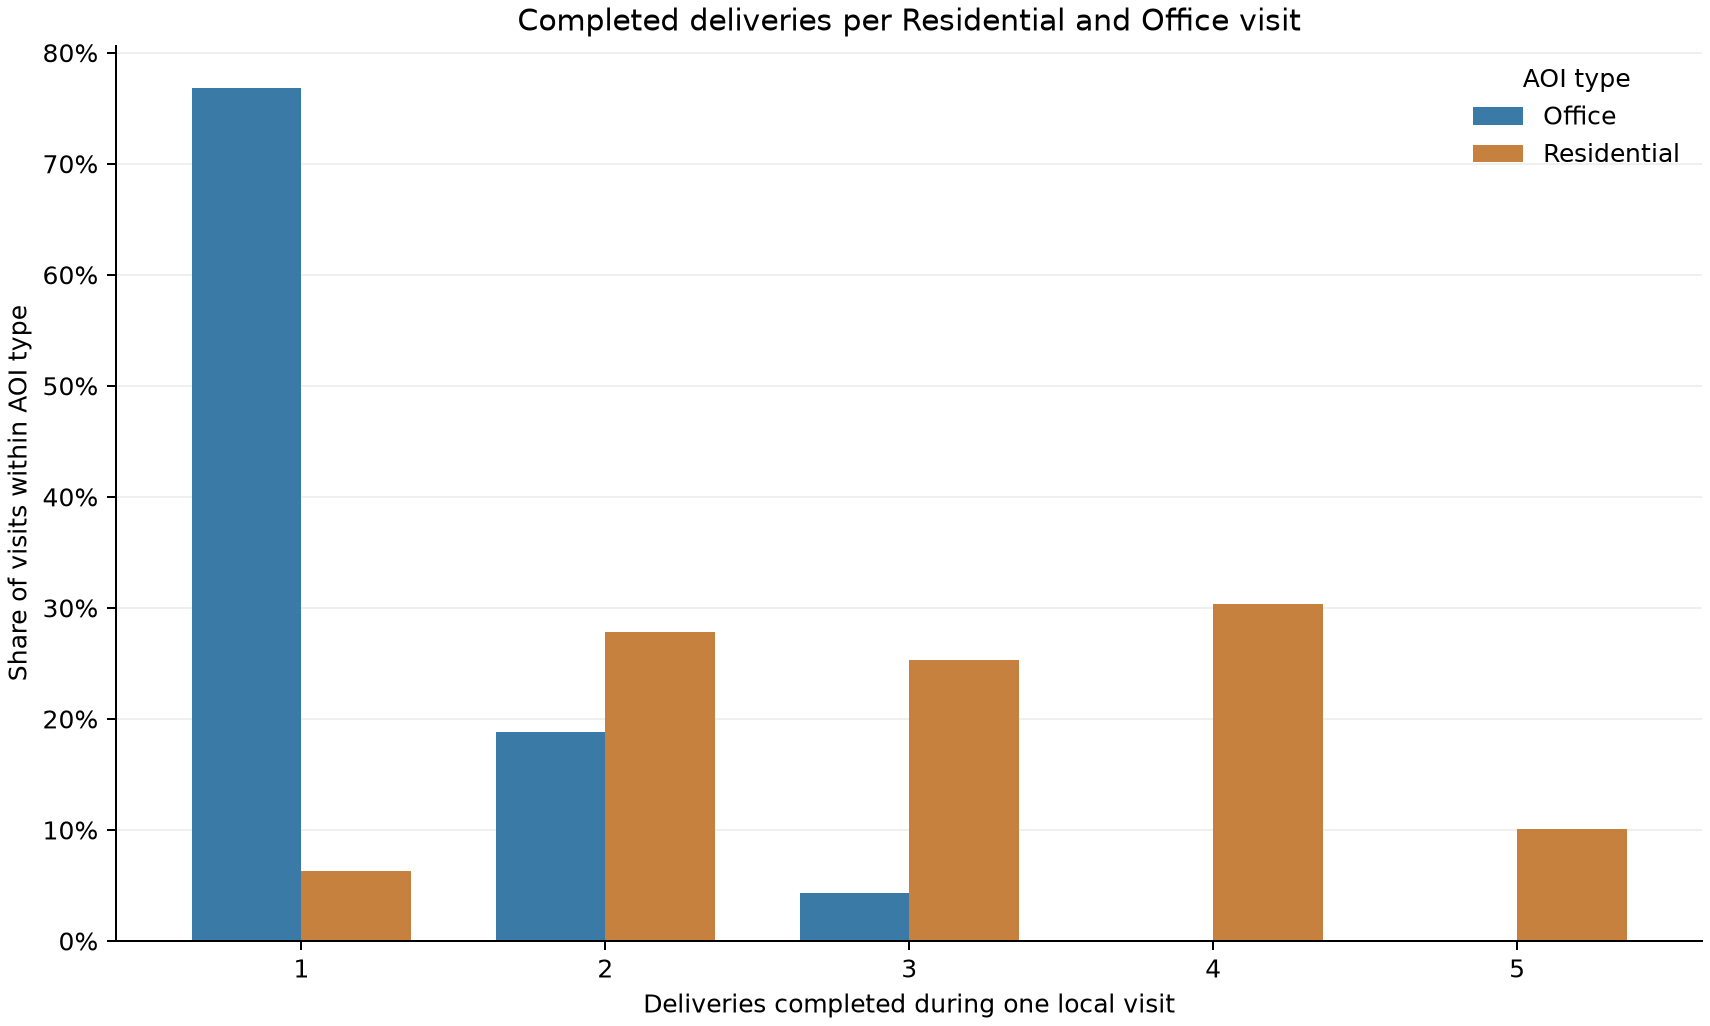

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


def visit_distribution(df):
    counts = pd.crosstab(df.completed_deliveries, df.aoi_type, normalize="columns")
    fig, ax = plt.subplots(figsize=(9.5, 5.7), constrained_layout=True)
    counts.reindex(range(1, int(df.completed_deliveries.max()) + 1), fill_value=0)[
        ["Office", "Residential"]
    ].plot.bar(ax=ax, rot=0, width=0.72, color=["#397aa7", "#c7813e"])
    ax.set(
        xlabel="Deliveries completed during one local visit",
        ylabel="Share of visits within AOI type",
        title="Completed deliveries per Residential and Office visit",
    )
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
    ax.legend(title="AOI type", frameon=False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    return counts.round(3)


print(visit_distribution(df))
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/aoi_delivery_batch_sizes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "aoi_visit_batch_size_distribution",
  "insight_type": "group_comparison",
  "insight": "Residential-AOI visits usually contain multiple completed deliveries, whereas Office-AOI visits usually contain a single completed delivery.",
  "insight_value": {
    "residential_batch_visit_rate": 0.937,
    "office_individual_visit_rate": 0.768,
    "workdays_per_aoi_type": 10
  },
  "plot": {
    "plot_type": "normalized_grouped_bars",
    "title": "Delivery Batch Sizes by AOI Type",
    "file": "visualizations/aoi_delivery_batch_sizes.png",
    "description": "Within-type visit shares compare the numbers of completed deliveries per Residential and Office visit across ten workdays."
  },
  "question": "How does the number of completed deliveries per visit differ between Residential and Office AOIs?",
  "actionable_insight": "Compare the within-type distribution of completed deliveries per local visit.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\n\ndef visit_distribution(df):\n    counts = pd.crosstab(df.completed_deliveries, df.aoi_type, normalize='columns')\n    fig, ax = plt.subplots(figsize=(9.5, 5.7), constrained_layout=True)\n    counts.reindex(range(1, int(df.completed_deliveries.max())+1), fill_value=0)[\n        ['Office', 'Residential']].plot.bar(ax=ax, rot=0, width=.72, color=['#397aa7', '#c7813e'])\n    ax.set(xlabel='Deliveries completed during one local visit', ylabel='Share of visits within AOI type',\n        title='Completed deliveries per Residential and Office visit')\n    ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')\n    ax.legend(title='AOI type', frameon=False)\n    ax.set_axisbelow(True); ax.grid(axis='y', alpha=.2)\n    ax.spines[['top', 'right']].set_visible(False)\n    return counts.round(3)\n\nprint(visit_distribution(df))\nplt.show()",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_type",
    "task_id",
    "courier_id",
    "completion_time",
    "delivery_position"
  ]
}

### **Question 2**: How do completed deliveries per visit and GPS travel distance per order differ between Residential and Office AOIs?

#### Analysis action

Divide each incoming GPS leg distance by its visit completion count and compare visit-level and AOI-level patterns.

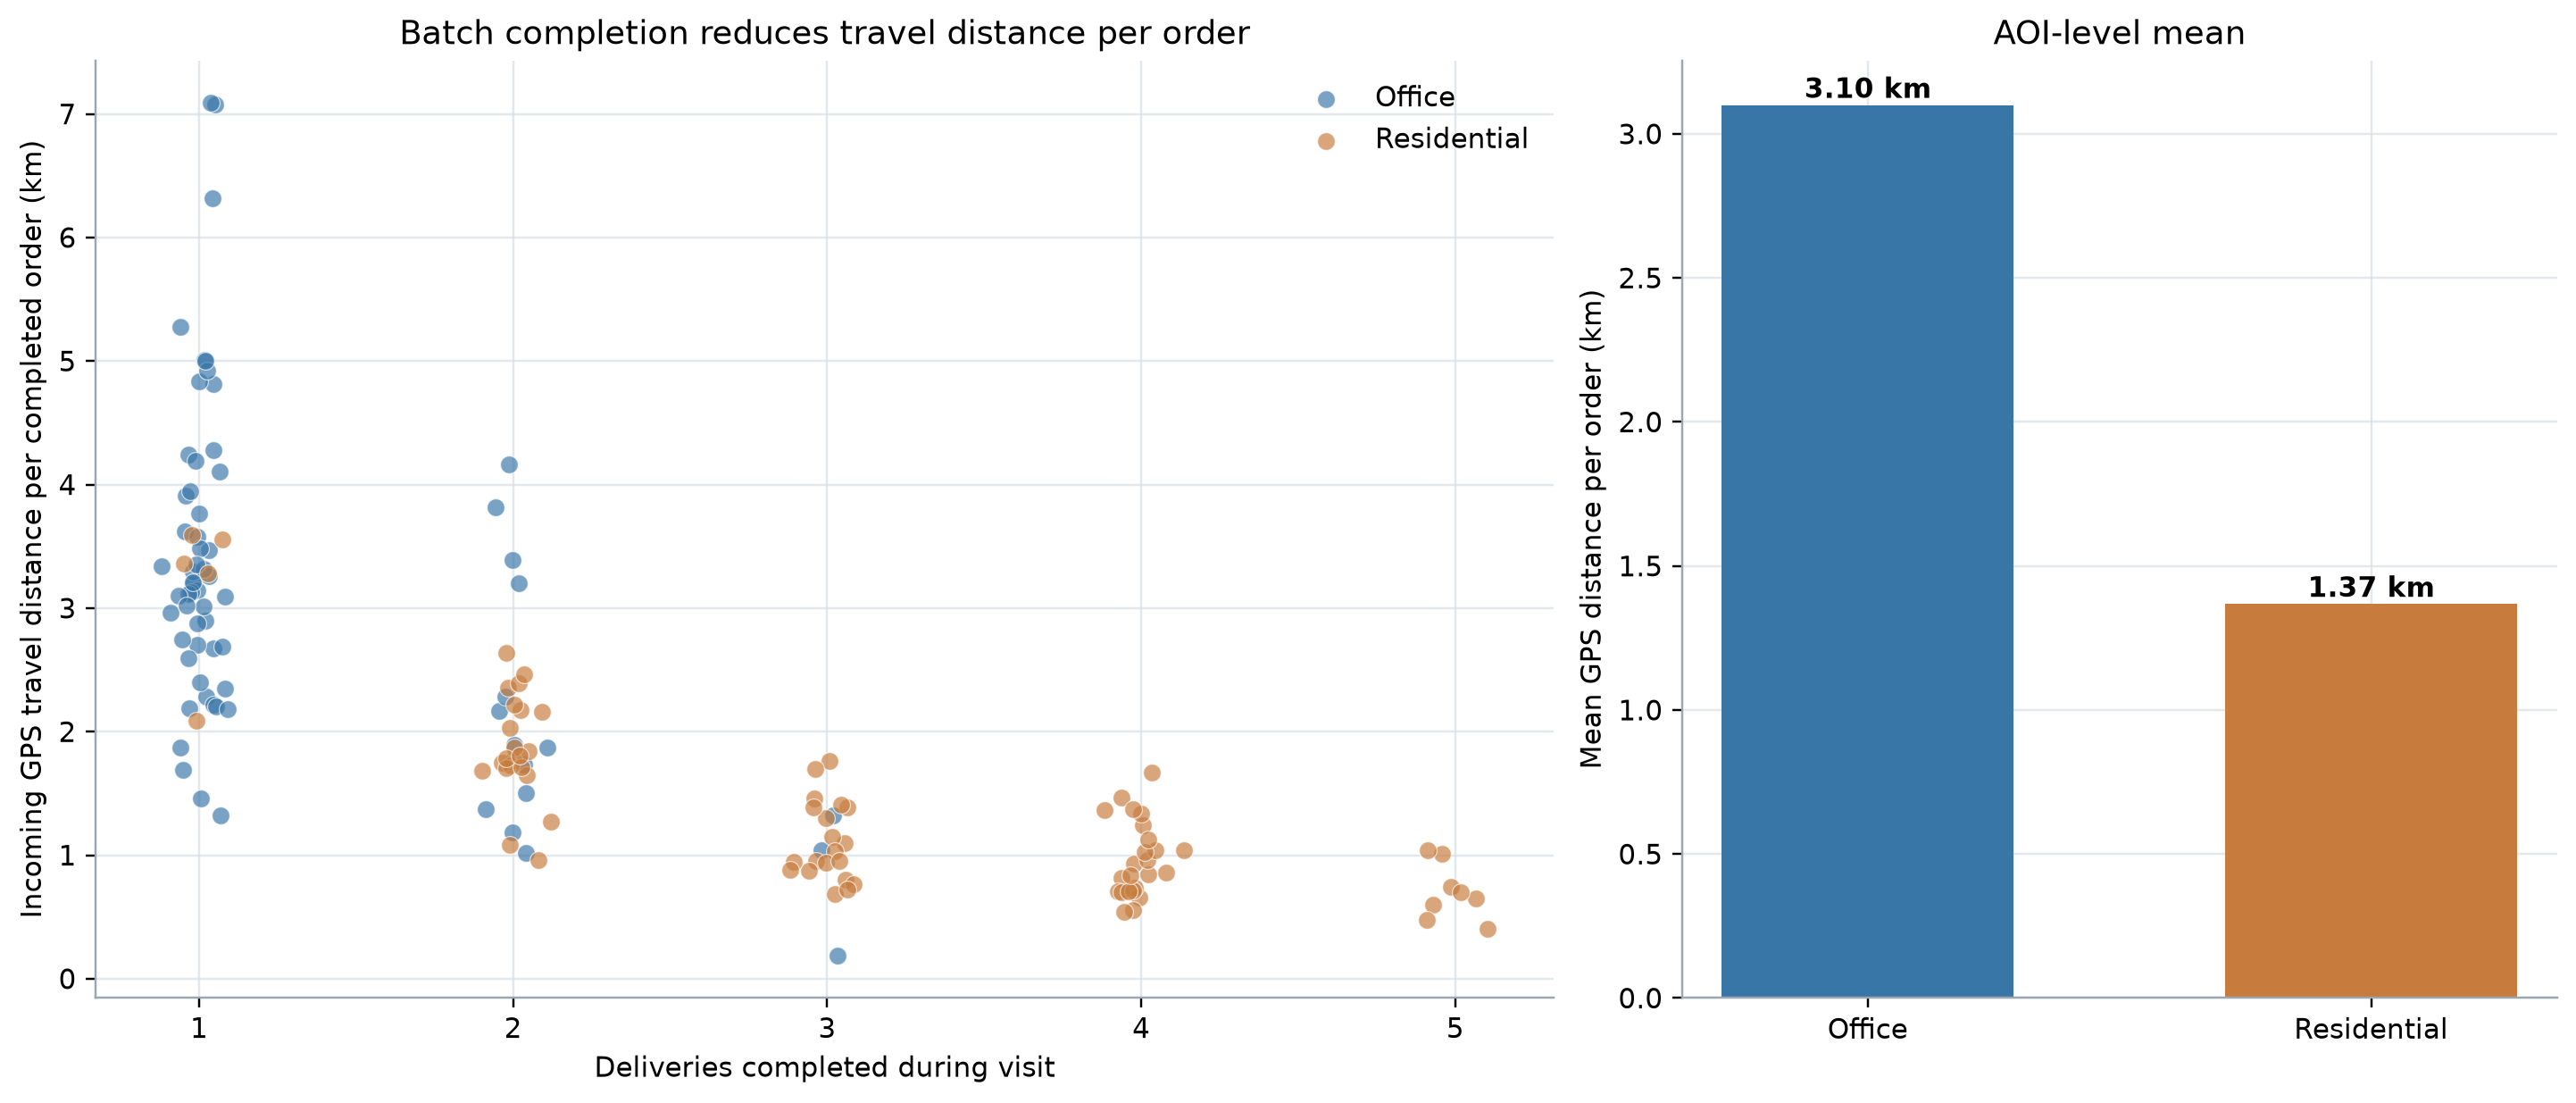

In [ ]:
print(
    df.groupby("aoi_type")[["completed_deliveries", "gps_distance_per_order_km"]]
    .agg(["count", "mean", "median"])
    .round(3)
)
print(df[["completed_deliveries", "gps_distance_per_order_km"]].corr().round(3))
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/aoi_batch_distance_efficiency.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "aoi_batch_size_and_gps_distance",
  "insight_type": "group_comparison",
  "insight": "Residential-AOI visits have more completed deliveries and lower incoming GPS travel distance per completed order than Office-AOI visits, on average.",
  "insight_value": {
    "mean_deliveries_per_visit": {
      "Office": 1.27,
      "Residential": 3.1
    },
    "mean_gps_distance_per_order_km": {
      "Office": 3.1,
      "Residential": 1.368
    },
    "visit_level_correlation": -0.74
  },
  "plot": {
    "plot_type": "visit_scatter_and_aoi_means",
    "title": "Batch Size and Travel Efficiency",
    "file": "visualizations/aoi_batch_distance_efficiency.png",
    "description": "All visit-level values are retained beside AOI-level mean travel distance per completed order."
  },
  "question": "How do completed deliveries per visit and GPS travel distance per order differ between Residential and Office AOIs?",
  "actionable_insight": "Divide each incoming GPS leg distance by its visit completion count and compare visit-level and AOI-level patterns.",
  "code": "print(df.groupby('aoi_type')[['completed_deliveries','gps_distance_per_order_km']].agg(['count','mean','median']).round(3));print(df[['completed_deliveries','gps_distance_per_order_km']].corr().round(3))",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_type",
    "task_id",
    "courier_id",
    "completion_time",
    "delivery_position",
    "gps_time",
    "gps_position"
  ]
}

### **Question 3**: At what times of day does the courier mainly serve Office and Residential AOIs?

#### Analysis action

Compare task completion-time distributions and visit arrival medians by AOI type.

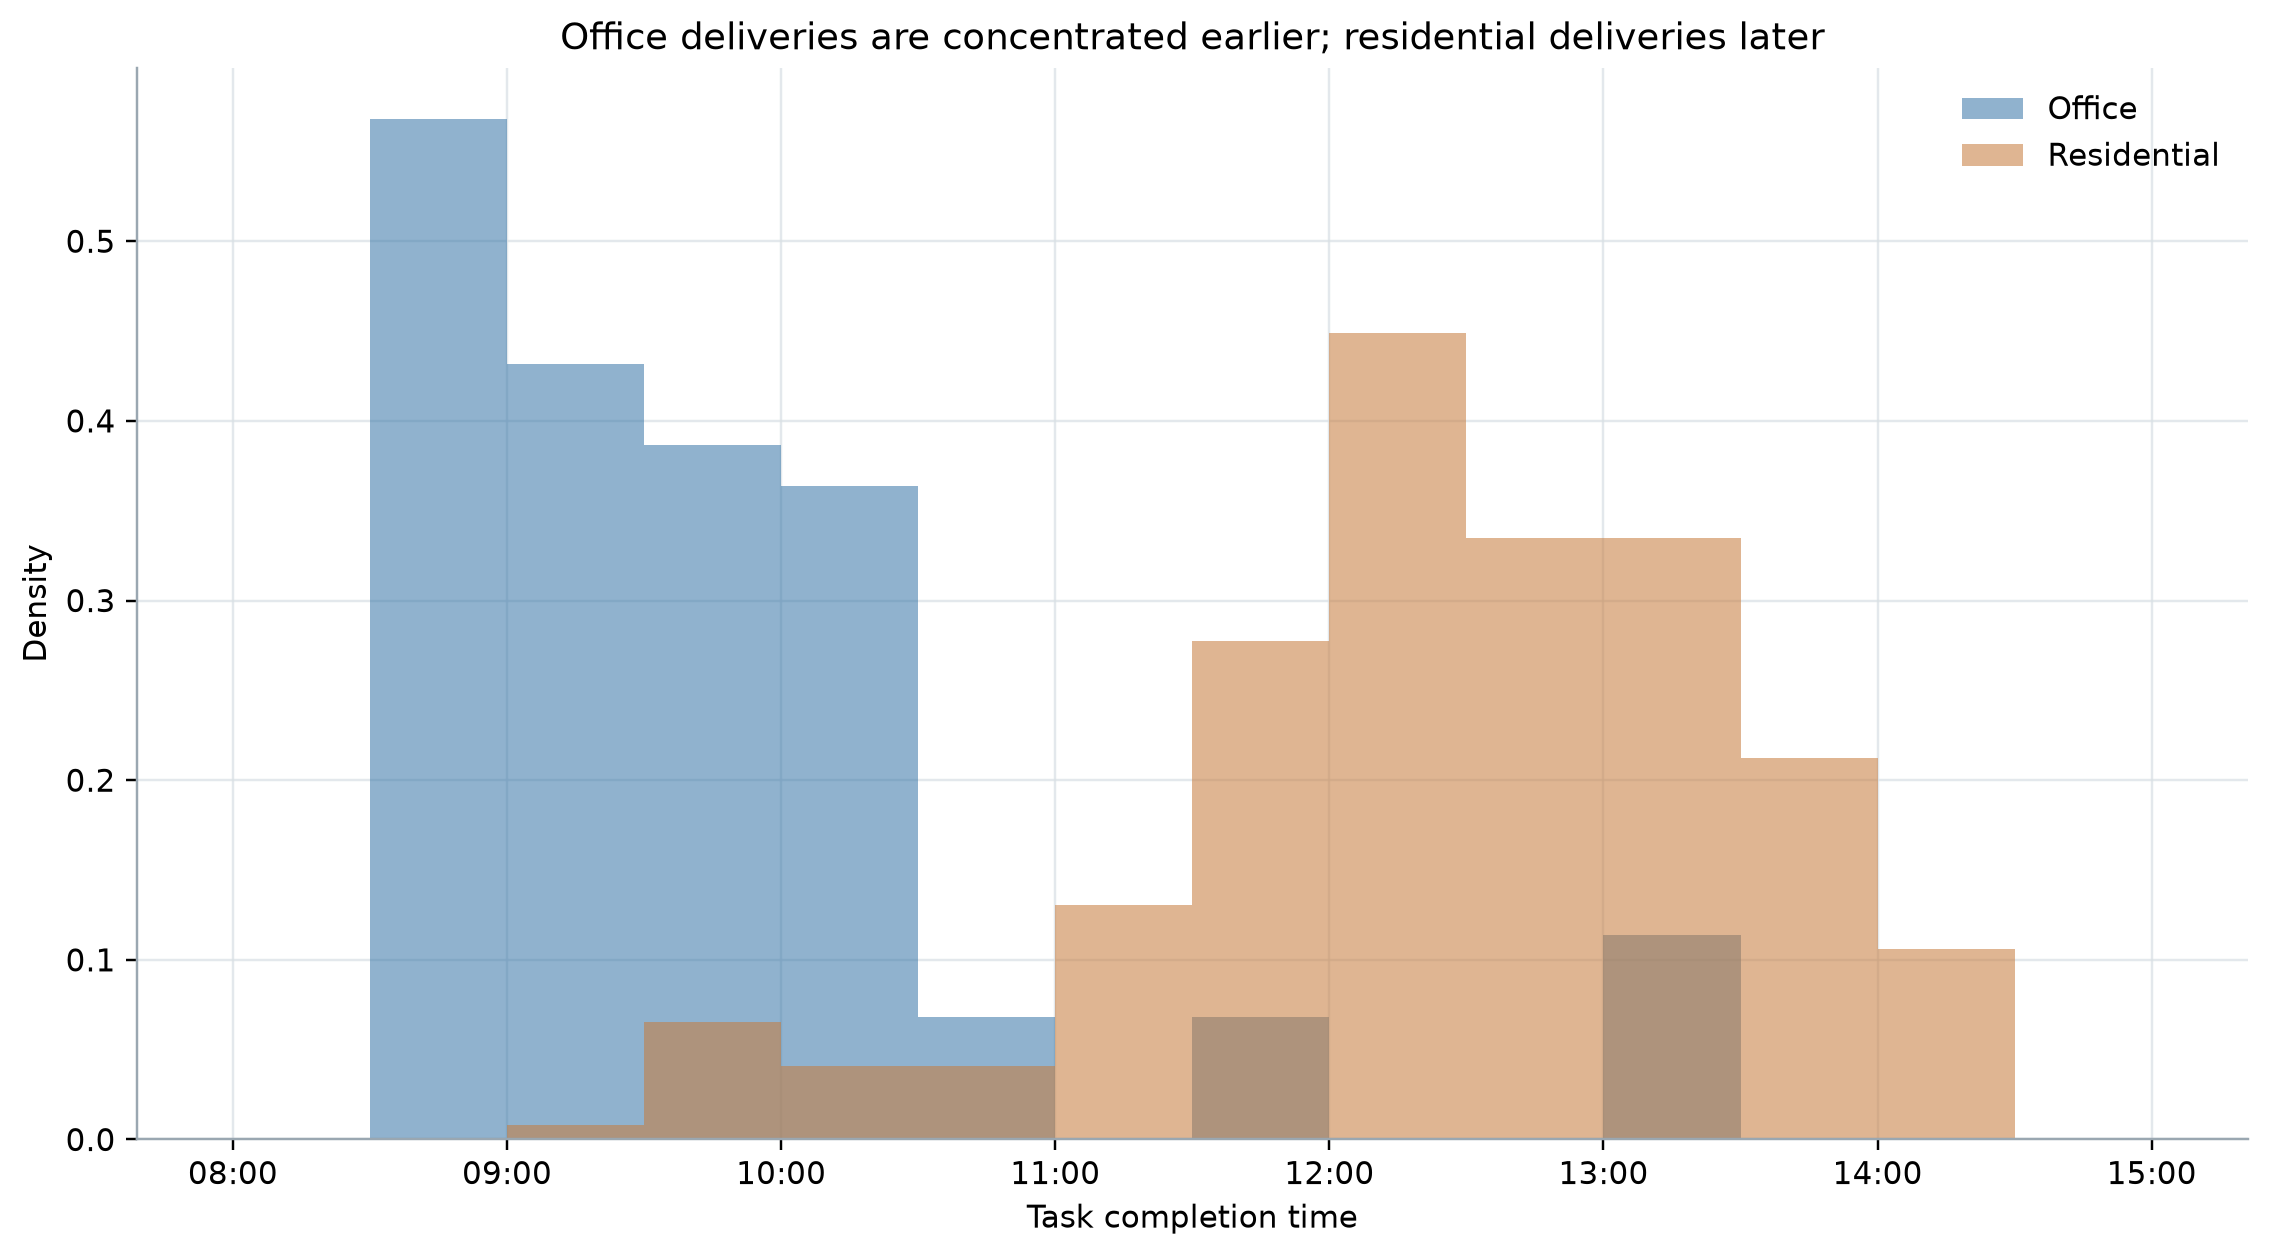

In [ ]:
d = df.copy()
d["arrival_time"] = pd.to_datetime(d.arrival_time)
d["hour"] = d.arrival_time.dt.hour + d.arrival_time.dt.minute / 60
print(d.groupby("aoi_type").hour.describe().round(2))
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/aoi_service_time_distribution.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "aoi_task_completion_time_distribution",
  "insight_type": "temporal_dynamics",
  "insight": "The courier mainly serves Office AOIs earlier in the workday and Residential AOIs later.",
  "insight_value": {
    "median_visit_arrival_hour": {
      "Office": 9.42,
      "Residential": 12.63
    }
  },
  "plot": {
    "plot_type": "overlapping_time_histograms",
    "title": "AOI Service Time",
    "file": "visualizations/aoi_service_time_distribution.png",
    "description": "Task-level completion-time distributions show an earlier office emphasis and later residential emphasis with natural overlap."
  },
  "question": "At what times of day does the courier mainly serve Office and Residential AOIs?",
  "actionable_insight": "Compare task completion-time distributions and visit arrival medians by AOI type.",
  "code": "d=df.copy();d['arrival_time']=pd.to_datetime(d.arrival_time);d['hour']=d.arrival_time.dt.hour+d.arrival_time.dt.minute/60;print(d.groupby('aoi_type').hour.describe().round(2))",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "aoi_type",
    "gps_time",
    "gps_position",
    "delivery_position",
    "courier_id",
    "completion_time",
    "task_id"
  ]
}

### Summary of Findings (Flag 14)

Residential-AOI visits usually contain multiple completed deliveries, whereas Office-AOI visits usually contain a single completed delivery. Residential-AOI visits have more completed deliveries and lower incoming GPS travel distance per completed order than Office-AOI visits, on average. The courier mainly serves Office AOIs earlier in the workday and Residential AOIs later.